# Medical Insurance Charges — Regression

The classic `insurance.csv` from Brett Lantz's *Machine Learning with R* — 1,338 rows, target is `charges` (the actual billed amount), features are age, sex, BMI, children, smoker flag, region.

Smoker status alone explains a huge chunk of variance — that's the well-known result on this dataset. The interesting modeling question is how much extra signal you get from the other variables once smoker is in the model.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score

import urllib.request
np.random.seed(0)
CSV = Path("../../data/medical_insurance/insurance.csv")
# public mirror from the book's companion dataset repo
URL = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"
if not CSV.exists():
    CSV.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(URL, CSV)
df = pd.read_csv(CSV)
print(df.shape)
df.describe(include="all").T


(1338, 7)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,1338.0,NaN,NaN,NaN,39.207025,14.04996,18.0,27.0,39.0,51.0,64.0
sex,1338,2,male,676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,1338.0,NaN,NaN,NaN,30.663397,6.098187,15.96,26.29625,30.4,34.69375,53.13
children,1338.0,NaN,NaN,NaN,1.094918,1.205493,0.0,0.0,1.0,2.0,5.0
smoker,1338,2,no,1064,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,1338,4,southeast,364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
charges,1338.0,NaN,NaN,NaN,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


## Quick EDA

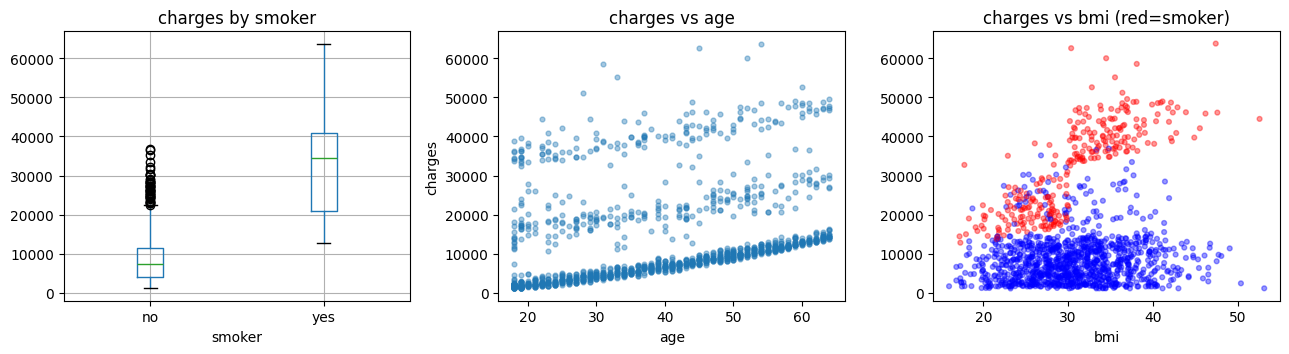

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
df.boxplot(column="charges", by="smoker", ax=axes[0]); axes[0].set_title("charges by smoker")
axes[1].scatter(df["age"], df["charges"], alpha=0.4, s=12); axes[1].set_xlabel("age"); axes[1].set_ylabel("charges")
axes[1].set_title("charges vs age")
axes[2].scatter(df["bmi"], df["charges"], c=(df.smoker=="yes").map({True:"red", False:"blue"}), alpha=0.4, s=12)
axes[2].set_xlabel("bmi"); axes[2].set_title("charges vs bmi (red=smoker)")
plt.suptitle(""); plt.tight_layout(); plt.show()
# note to self: smokers form a clearly separated band, especially as BMI goes up.


## Models

In [3]:
X = pd.get_dummies(df.drop(columns=["charges"]), drop_first=True).astype(float)
feature_names = X.columns.tolist()
X = X.values
y = df["charges"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)

models = {
    "Linear":           (LinearRegression(),                                            X_train_s, X_test_s),
    "Ridge":            (Ridge(alpha=1.0),                                              X_train_s, X_test_s),
    "RandomForest":     (RandomForestRegressor(n_estimators=400, random_state=0, n_jobs=-1), X_train, X_test),
    "GradientBoosting": (GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=0),
                         X_train, X_test),
}

for name, (m, Xtr, Xte) in models.items():
    m.fit(Xtr, y_train)
    pred = m.predict(Xte)
    print(f"{name:18s}  R^2={r2_score(y_test, pred):.3f}  MAE=${mean_absolute_error(y_test, pred):,.0f}")


Linear              R^2=0.800  MAE=$3,933
Ridge               R^2=0.800  MAE=$3,935


RandomForest        R^2=0.881  MAE=$2,573


GradientBoosting    R^2=0.893  MAE=$2,504


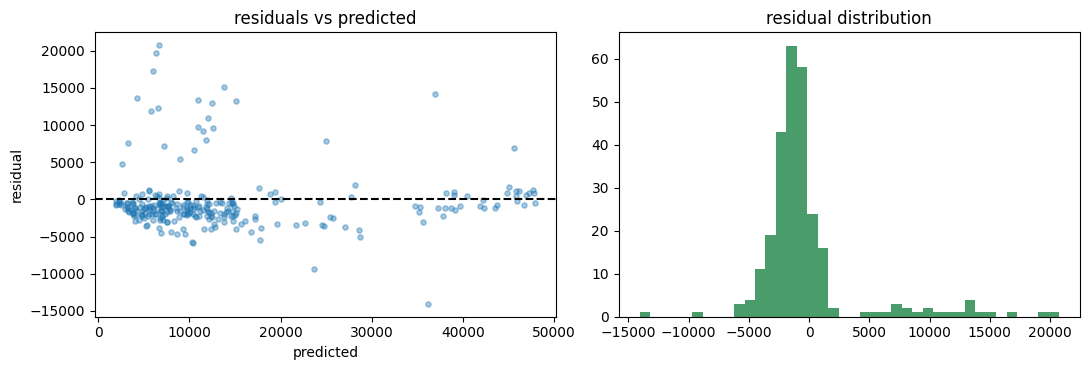

In [4]:
# residuals on the best (usually GB) model
gb = models["GradientBoosting"][0]
pred = gb.predict(X_test)
resid = y_test - pred

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].scatter(pred, resid, alpha=0.4, s=14); axes[0].axhline(0, color="k", ls="--")
axes[0].set_xlabel("predicted"); axes[0].set_ylabel("residual"); axes[0].set_title("residuals vs predicted")
axes[1].hist(resid, bins=40, color="#4a9c6a"); axes[1].set_title("residual distribution")
plt.tight_layout(); plt.show()


## Takeaways

The headline story on this dataset has been consistent across every analysis I've seen:

1. Smoker is by far the single strongest predictor. A linear regression with just `smoker` gets you most of the way.
2. BMI matters mostly *through* smoker — high-BMI smokers blow up the charges in a way that's not linear.
3. Age contributes a roughly linear ramp; sex and region barely move the needle.

On the 268-row test split, gradient boosting reaches R^2 0.893 (MAE about $2,500) against 0.800 (MAE about $3,930) for plain linear regression. Most of that gap is the smoker × BMI interaction. A linear model can capture that too if you explicitly add an interaction term, but the tree models pick it up for free.

Residuals are not super clean — there's heteroscedasticity, with high predictions having wider residual spread. A log-transform on the target (`log1p(charges)`) tends to tighten things up if you care about MAPE rather than MAE. I didn't bother for this notebook because the comparison was already informative.
